# Torsion partitioning

`cut_clustering(fit)` partitions a torsional ensemble by cutting one-dimensional free-energy profiles,
recursively, until no cut is left that clears a barrier. Every region it produces is a **cell**, bounded by
cuts, and the cells that are not cut again are the clusters. No HDBSCAN is run, and every frame gets a
label: there is no noise and no ambiguous code. `fit` is a `t_hdbscan(...)` object, fitted or not; only
its angles and, on the symmetry-first route, its symmetry operations are read.

```text
symmetry-invariant coordinates -> empty-bin cuts -> annealed barrier cuts, E* from F_max down to kT_cut
                                                                   -> cells -> clusters 0, 1, ... by mass
```

1. **Coordinates.** A torsion no symmetry operation moves is its own coordinate; torsions an operation
   moves together are replaced by symmetry-invariant averages (see
   [Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#6-symmetry-invariant-coordinates-used-by-torsion-partitioning)).
2. **Empty-bin cuts**, recursively, wherever both sides keep at least `mass_floor` of all frames.
3. **Annealing.** Each cell starts at E* = the largest finite free-energy range of any coordinate in it,
   and lowers E* by `kT_step` down to `kT_cut`. At each E* the cell is cut on the coordinate with the
   highest barrier that clears E*; both children continue from that E*.
4. **Numbering** by mass, largest first.

| parameter | default | what it sets | section |
|---|---|---|---|
| `kT_cut` | 1.0 | the lowest barrier, in kT, that is cut | [3](#3-kt_cut-the-lowest-barrier) |
| `mass_floor` | 0.001 | the smallest piece a cut may leave, as a fraction of ALL frames | [4](#4-mass_floor-the-smallest-piece) |
| `min_p2p` | π/3 | the smallest cut-to-cut distance, in radians | [5](#5-min_p2p-the-smallest-cut-to-cut-distance) |
| `kT_step` | 0.5 | how fast E* is lowered | [6](#6-kt_step-the-annealing-step) |
| `n_bins` | 72 | the histogram (5 degree bins); cuts sit at bin midpoints | [7](#7-n_bins-the-histogram) |
| `z_min` | 0.5 | where a symmetry-invariant coordinate is too weak to use | [8](#8-z_min-gauge-and-reference) |
| `gauge`, `reference` | None, 0 | how `aligned_angles` are written for drawing; never the cells | [8](#8-z_min-gauge-and-reference) |

`kT_cut` is in kT and needs no temperature: 1 kT is 0.60 kcal/mol at 300 K.

**The example** is alanine dipeptide, all 100 000 frames of the 1 us cMD run of the
[ALA tutorial](https://csy0000.github.io/MD-tools/tutorial/ALA/), on phi and psi, through the default symmetry-first route.
No symmetry operation moves phi or psi, so the coordinates are phi and psi themselves.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[2] / "tutorial" / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
import tutorial_data as td
import md_tools
from md_tools.analysis import (t_hdbscan, cut_clustering, plot_split_tree, plot_hist,
                               TorsionDefinitions, verify_atom_mapping)

# Where the runs are is NOT printed: these pages are committed with their outputs.
print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING", "| md-tools", md_tools.__version__)

tutorial runs: found | md-tools 0.6.5.2


In [2]:
traj = td.solute("ALA-1us")
mol = td.molecule_from_topology(traj)
mapping, why = verify_atom_mapping(mol, [(a.index, b.index) for a, b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
phi_atoms, phi = md.compute_phi(traj)
psi_atoms, psi = md.compute_psi(traj)
definitions = TorsionDefinitions(quads=(tuple(phi_atoms[0]), tuple(psi_atoms[0])), names=("phi", "psi"),
                                 indexing="zero-based", units="radian")
tors = np.column_stack([phi[:, 0], psi[:, 0]])
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj, atom_mapping=mapping)
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", why, "|", len(tors), "frames")

H, xe, ye = np.histogram2d(np.degrees(tors[:, 0]), np.degrees(tors[:, 1]), bins=72, range=[[-180, 180], [-180, 180]])
F2 = -np.log(np.where(H > 0, H / H.sum(), np.nan)); F2 -= np.nanmin(F2)
SHOW = np.arange(0, len(tors), 5)                    # every 5th frame is drawn

def rama(ax, r, title):
    """The free energy of the run in grey, every 5th frame coloured by its cell."""
    ax.pcolormesh(xe, ye, F2.T, cmap="Greys_r", vmin=0, vmax=10, shading="auto", alpha=0.35)
    d = np.degrees(tors[SHOW])
    lab = r["labels"][SHOW]
    for c in range(r["n_clusters"]):
        m = lab == c
        ax.scatter(d[m, 0], d[m, 1], s=1.5, color=f"C{c % 10}", rasterized=True,
                   label=f"{c + 1} ({100 * r['cluster_mass'][c]:.2f} %)")
    ax.set(xlim=(-180, 180), ylim=(-180, 180), xticks=[-180, -90, 0, 90, 180], yticks=[-180, -90, 0, 90, 180],
           xlabel="phi (deg)", ylabel="psi (deg)", title=title)
    ax.legend(fontsize=7, markerscale=5, loc="lower right")

def summary(r):
    return {"clusters": r["n_clusters"],
            "masses (%)": [round(100 * m, 2) for m in r["cluster_mass"].values()],
            "cuts": len(r["cuts"])}

def sweep(name, values, show):
    results = {v: cut_clustering(fit, **{name: v}) for v in values}
    fig, axes = plt.subplots(1, len(show), figsize=(5.7 * len(show), 5.2), layout="constrained")
    for ax, v in zip(np.atleast_1d(axes), show):
        rama(ax, results[v], f"{name} = {v:g}")
    plt.show()
    display(pd.DataFrame([{name: v, **summary(r)} for v, r in results.items()]))
    return results

CNC(=O)[C@H](C)NC(C)=O | identity verified: elements and the full bond graph agree under this mapping | 100000 frames


## 1. The default partition

100000 frames: periodic cut on phi (empty bins) -> 2759 + 97241
  2759 frames: periodic cut on psi (empty bins) -> 2574 + 185
  97241 frames: periodic cut on psi (barrier 3.39 kT at E*=2.93) -> 29832 + 67409
    67409 frames: bounded cut on phi (barrier 1.15 kT at E*=1.00) -> 12812 + 54597


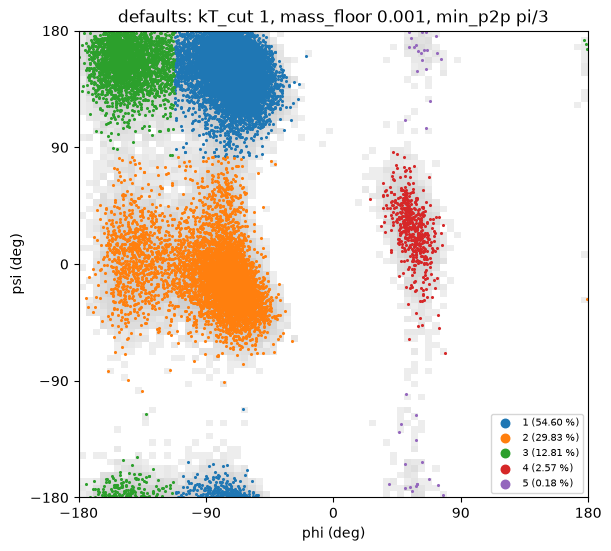

,clusters,masses (%),cuts
0,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4


In [3]:
result = cut_clustering(fit)
print("\n".join(result["log"]))
fig, ax = plt.subplots(figsize=(6, 5.4), layout="constrained")
rama(ax, result, "defaults: kT_cut 1, mass_floor 0.001, min_p2p pi/3")
plt.show()
pd.DataFrame([summary(result)])

Five clusters: PPII, alpha-R, beta, alpha-L and a 0.18 % strip at phi near 60, psi near 180. The log is the
tree, one line per cut. The splitting tree draws it: every cell, the 2D histogram of its frames with the 1D
densities on two edges, the cut made there in red and the boundaries the cell inherited in grey.

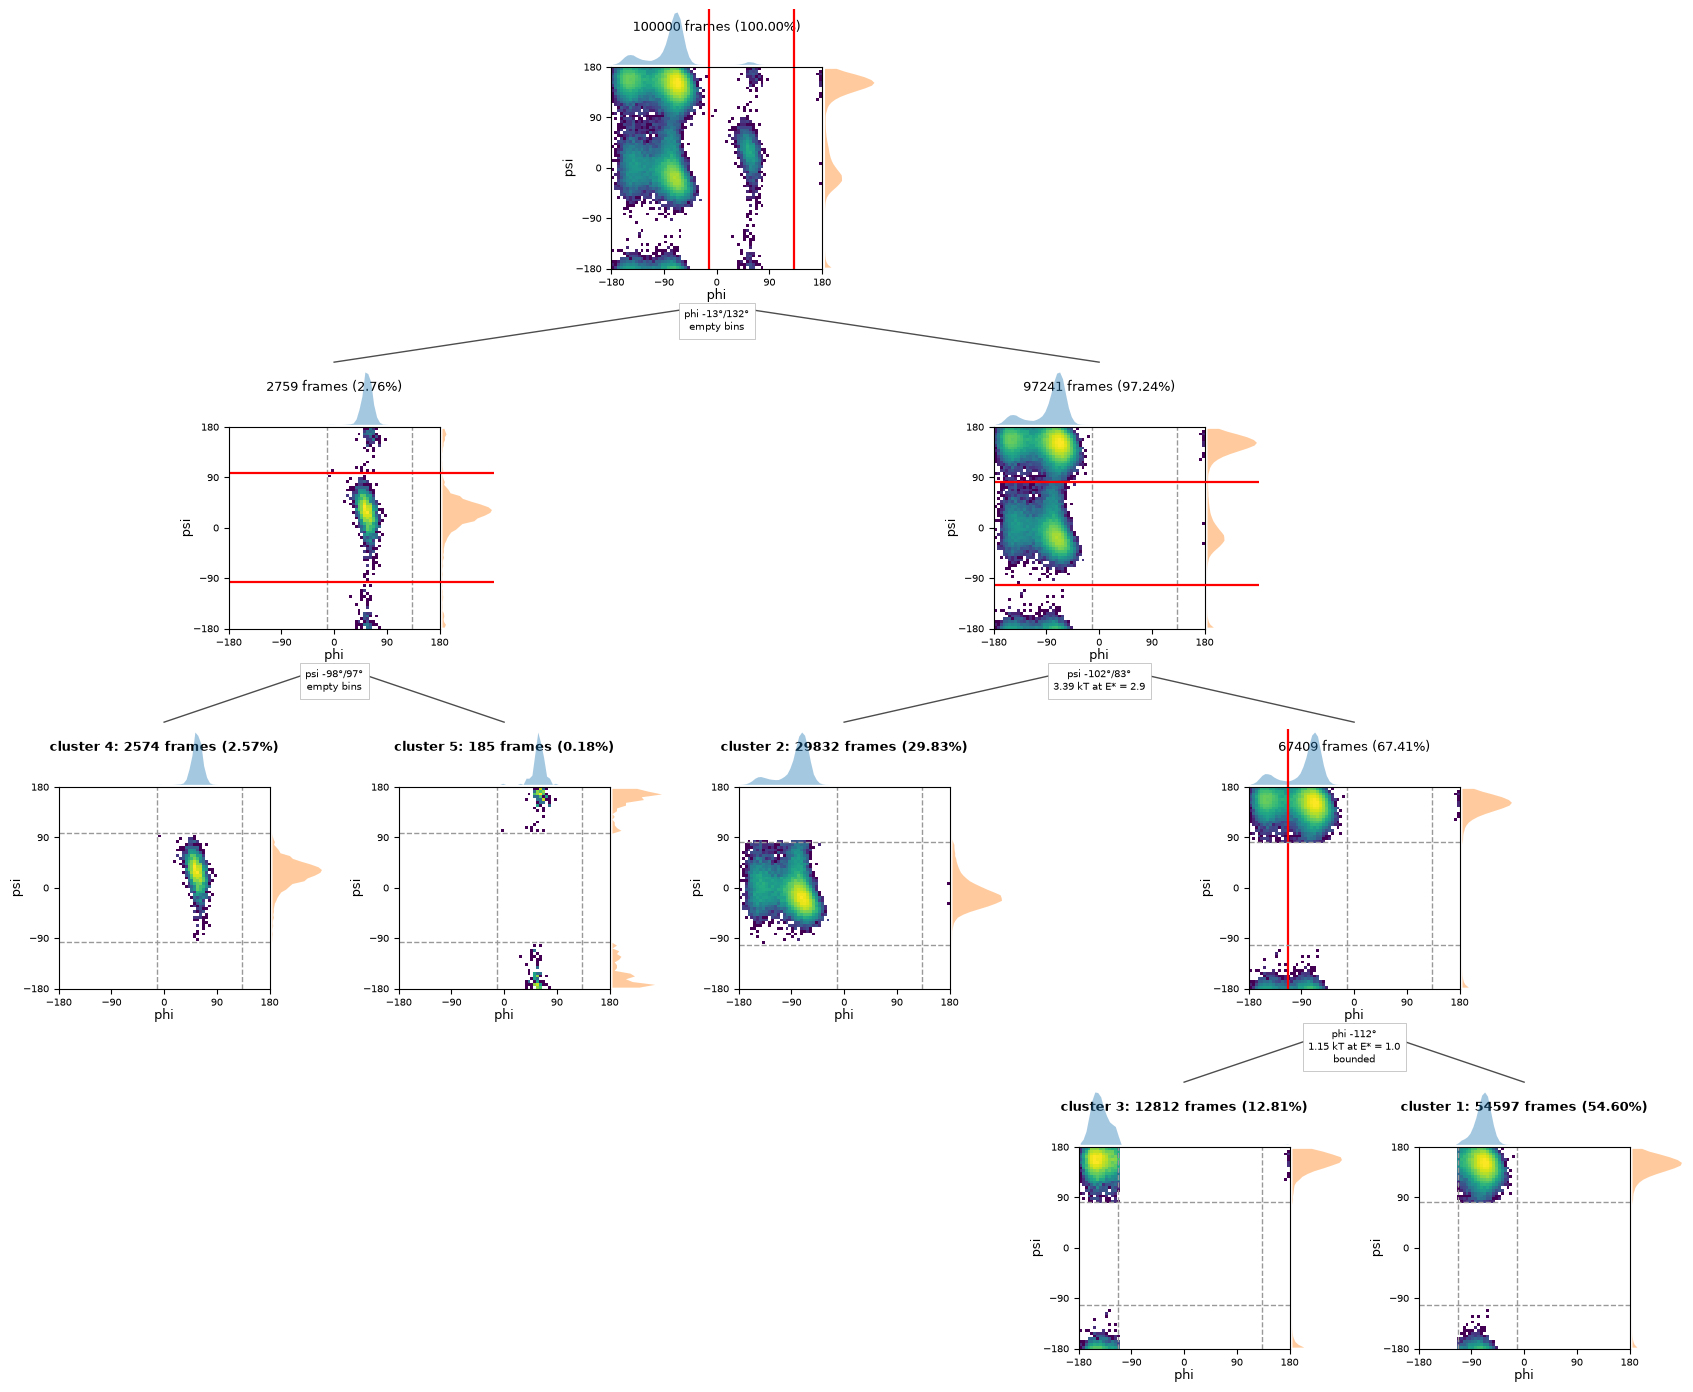

In [4]:
plot_split_tree(result, pair=("phi", "psi"));

The first two cuts go through empty bins: phi near -13 and 132 degrees separates the positive-phi region,
and psi then separates alpha-L from the strip. The rest are barrier cuts: psi (3.39 kT) separates alpha-R from
the beta/PPII cell, and phi at -112 degrees (1.15 kT) separates beta from PPII. That last cut is **bounded**:
phi was already cut in this cell's ancestry, so the cell lives on one arc of phi and takes one cut inside it.

## 2. How one cut is chosen

On one coordinate of one cell, F = -ln p in kT on `n_bins` bins over the circle. A cut sits at a bin's
**midpoint**, so it is a dividing surface and no frame is left over.

* **Periodic**: a coordinate not yet cut in the cell's ancestry. A circle needs two cuts to make two pieces.
  Cut 1 is the centre of the highest plateau (an empty bin ranks above every filled one); cut 2 is the
  highest-F bin more than `min_p2p` from cut 1 whose barrier clears E*.
* **Bounded**: a coordinate already cut. The cell lives on the arc between two inherited cuts, the search
  is limited to that arc, and one cut suffices. Both pieces, measured along the arc up to the inherited
  boundaries, must be wider than `min_p2p`. The highest-F bin that qualifies is taken; among equal F (a run
  of empty bins), the one leaving the larger smaller side.
* **The barrier** of a cut is its F minus the lowest F of the smaller side (for two cuts, the lower of the
  two F values). Both sides must hold at least `mass_floor` of all frames.
* **Across coordinates**, the cell is cut on the coordinate whose cut has the highest barrier; ties go to
  coordinate order.

The two barrier cuts of the tree above, on their own cells:

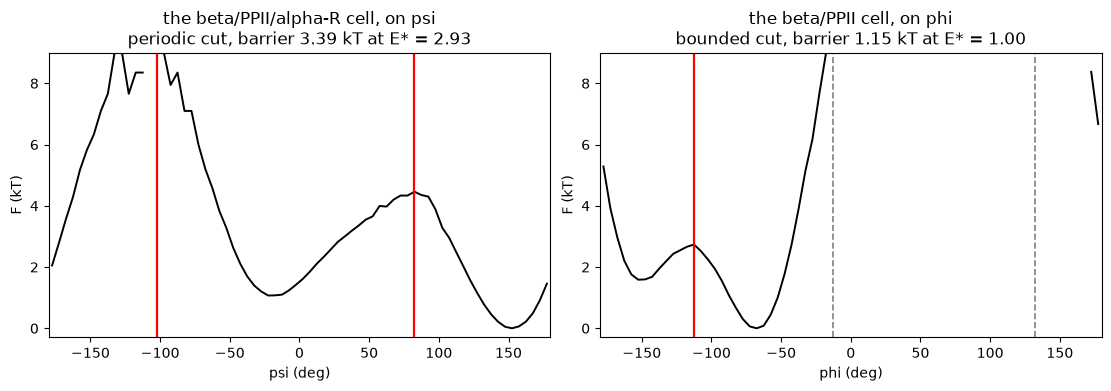

In [5]:
def cell_rows(r, node):
    tree = r["tree"]
    def leaves(i):
        return [tree[i]["cluster"]] if not tree[i]["children"] else sum((leaves(c) for c in tree[i]["children"]), [])
    return np.flatnonzero(np.isin(r["labels"], leaves(node)))

def profile(ax, r, node, title):
    cut = r["tree"][node]["cut"]
    j = r["coordinates"].index(cut["coordinate"])
    x = np.degrees(r["coordinate_values"][cell_rows(r, node), j])
    edges = np.linspace(-180, 180, r["settings"]["n_bins"] + 1)
    count = np.histogram(x, edges)[0].astype(float)
    with np.errstate(divide="ignore"):
        F = -np.log(count / count.sum())
    F -= F[np.isfinite(F)].min(); F[~np.isfinite(F)] = np.nan
    centres = 0.5 * (edges[1:] + edges[:-1])
    ax.plot(centres, F, "k-", lw=1.4)
    for v in cut["positions_degrees"]:
        ax.axvline(v, color="r", lw=1.6)
    for v in (r["tree"][node]["box_degrees"][cut["coordinate"]] or ()):
        ax.axvline(v, color="0.5", ls="--", lw=1.2)
    ax.set(xlim=(-180, 180), ylim=(-0.3, 9), xlabel=f"{cut['coordinate']} (deg)", ylabel="F (kT)",
           title=f"{title}\n{cut['kind']} cut, barrier {cut['barrier_kT']:.2f} kT at E* = {cut['level_kT']:.2f}")

barrier_nodes = [c["node"] for c in result["cuts"] if c["barrier_kT"] is not None]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, node, title in zip(axes, barrier_nodes, ("the beta/PPII/alpha-R cell, on psi", "the beta/PPII cell, on phi")):
    profile(ax, result, node, title)
plt.show()

Red: the cut. Grey dashed: the inherited boundaries of the bounded cell on phi; outside them the cell has no
frames. On the right the lowest F of the smaller side (beta, phi near -150) is 1.15 kT below the cut.

## 3. `kT_cut`: the lowest barrier

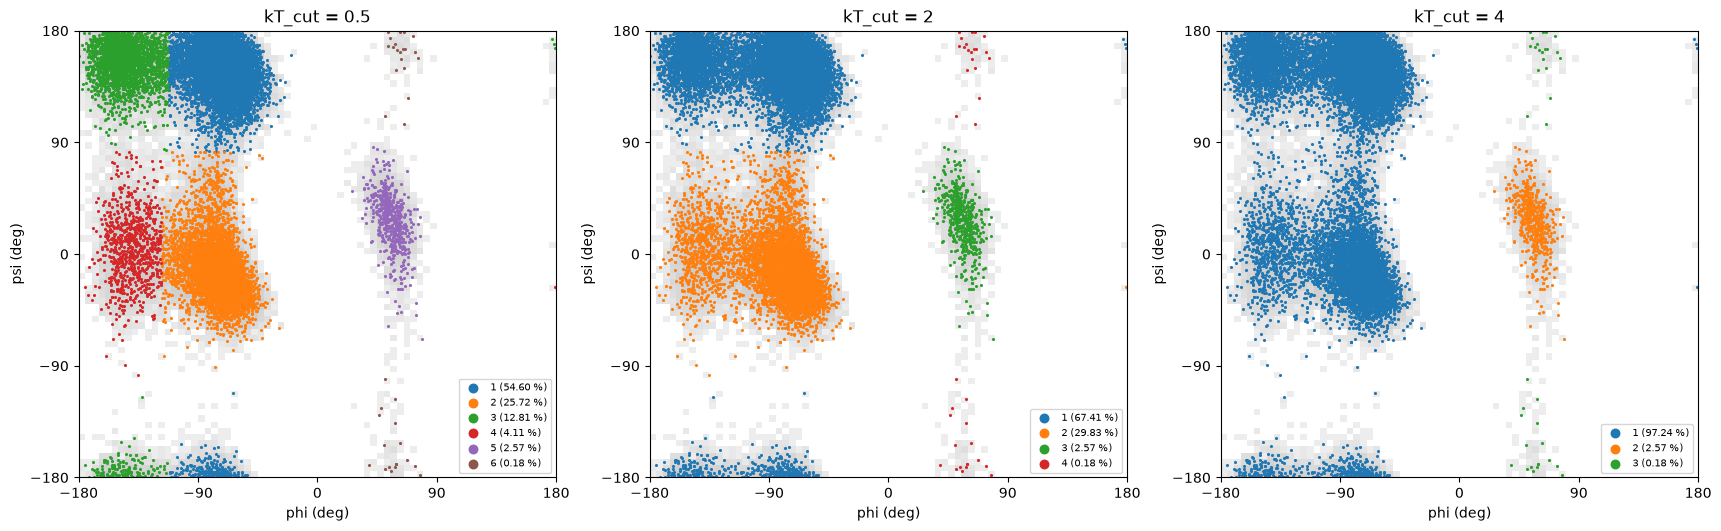

,kT_cut,clusters,masses (%),cuts
0,0.5,6,"[54.6, 25.72, 12.81, 4.11, 2.57, 0.18]",5
1,1.0,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
2,2.0,4,"[67.41, 29.83, 2.57, 0.18]",3
3,3.0,4,"[67.41, 29.83, 2.57, 0.18]",3
4,4.0,3,"[97.24, 2.57, 0.18]",2


In [6]:
by_kT = sweep("kT_cut", (0.5, 1.0, 2.0, 3.0, 4.0), show=(0.5, 2.0, 4.0))

At 0.5 kT alpha-R loses its left shoulder (a bounded phi cut of 0.50 kT); at 2 and 3 kT beta and PPII stay
together (their barrier is 1.15 kT); at 4 kT alpha-R joins them too (3.39 kT). The empty-bin cuts do not
depend on `kT_cut`: alpha-L and the strip are separated at every value. `kT_cut` is the one parameter that
says what a state is, and it is stated in the units the barrier is read in.

## 4. `mass_floor`: the smallest piece

Both sides of every cut must hold `mass_floor` of **all** frames, not of the cell's, so the floor means the
same mass at every depth of the tree. The default 0.1 % is ten times lower than HDBSCAN's 1 %: the floor
here only refuses cuts, while a barrier has to be there for a cut to be made at all.

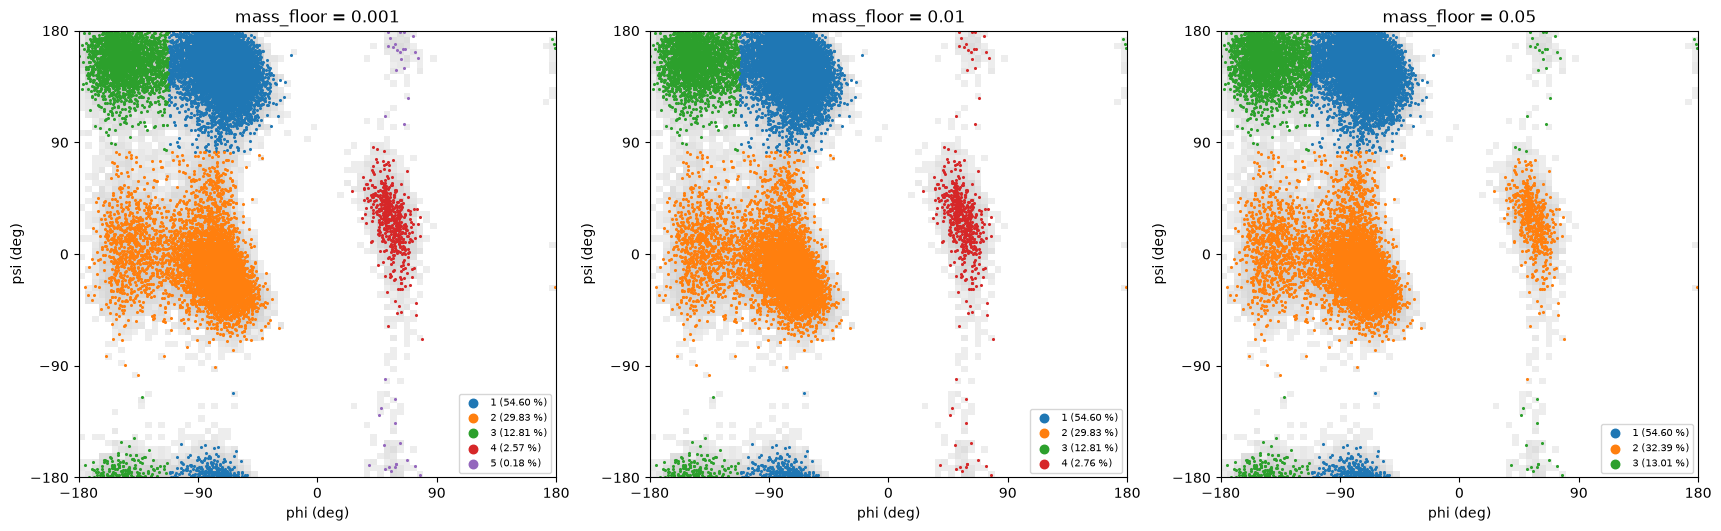

,mass_floor,clusters,masses (%),cuts
0,0.0001,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
1,0.0010,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
2,0.0100,4,"[54.6, 29.83, 12.81, 2.76]",3
3,0.0500,3,"[54.6, 32.39, 13.01]",2


In [7]:
by_floor = sweep("mass_floor", (0.0001, 0.001, 0.01, 0.05), show=(0.001, 0.01, 0.05))

At 1 % the 0.18 % strip may not be cut off, and stays with alpha-L. At 5 % alpha-L itself (2.6 %) is under the
floor: the empty-bin cut that isolated it is refused, and the first cut is the psi barrier. alpha-L ends up
with alpha-R and the strip with beta, on whichever side of the psi cut they lie. A cut refused by the floor is refused, not moved: the frames stay with the cell they are in,
whatever the empty bins between them.

## 5. `min_p2p`: the smallest cut-to-cut distance

Two cuts closer than `min_p2p` would make a sliver. On a periodic coordinate the two cuts must be more than
`min_p2p` apart; on a bounded one, both pieces must be wider than `min_p2p`, measured along the arc to the
inherited boundaries. The default is pi/3 (60 degrees); exactly 60 degrees is refused.

On ALA it acts on one cut, the bounded phi cut between beta and PPII. The cell's phi arc runs from 132 to
-13 degrees through 180, 215 degrees wide, and the cut at -112 degrees leaves pieces of 115 and 100 degrees:

pieces either side of the phi cut (deg): [115.0, 100.0]


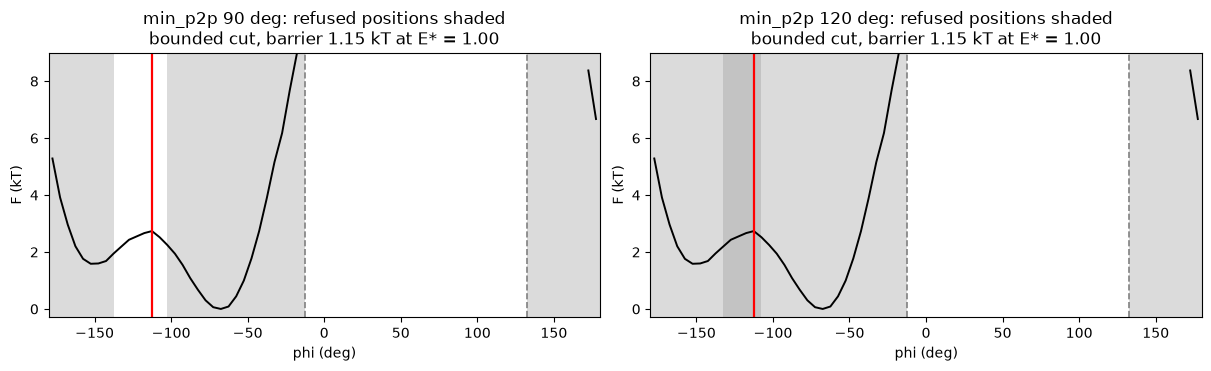

,min_p2p (deg),clusters,masses (%),cuts
0,0,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
1,30,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
2,60,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
3,90,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
4,120,4,"[67.41, 29.83, 2.57, 0.18]",3


In [8]:
node = barrier_nodes[1]
cut = result["tree"][node]["cut"]
print("pieces either side of the phi cut (deg):", cut["child_widths_degrees"])
lo, hi = result["tree"][node]["box_degrees"]["phi"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
for ax, p2p in zip(axes, (90, 120)):
    profile(ax, result, node, f"min_p2p {p2p} deg: refused positions shaded")
    for start in (lo, hi - p2p):                     # within min_p2p of either inherited boundary
        a, b = (start + 180) % 360 - 180, (start + p2p + 180) % 360 - 180
        for s, e in ([(a, b)] if a < b else [(a, 180), (-180, b)]):
            ax.axvspan(s, e, color="0.6", alpha=0.35, lw=0)
plt.show()
by_p2p = {v: cut_clustering(fit, min_p2p=v) for v in (0.0, np.pi / 6, np.pi / 3, np.pi / 2, 2 * np.pi / 3)}
pd.DataFrame([{"min_p2p (deg)": round(np.degrees(v)), **summary(r)} for v, r in by_p2p.items()])

Up to 90 degrees both pieces are wide enough and nothing changes. At 120 degrees the two refused zones
overlap and cover the whole arc: no position leaves two pieces that wide, and beta stays with PPII. On ALA every other cut has its partner far away, so
`min_p2p` is a guard against slivers rather than a knob: lowering it to 0 changes nothing here. On a
coordinate with a narrow empty run beside a well it is what keeps a cell from being cut twice into a strip.

## 6. `kT_step`: the annealing step

E* starts at the largest free-energy range in the cell and is lowered by `kT_step`. At each E* only cut
positions whose barrier clears E* are candidates, so a large E* admits only the deepest positions. With a
very large step the first level below the start is `kT_cut` itself:

In [9]:
for step in (0.5, 100.0):
    r = cut_clustering(fit, kT_step=step)
    print(f"kT_step = {step}: {r['n_clusters']} clusters")
    print("\n".join("    " + line for line in r["log"]))

kT_step = 0.5: 5 clusters
    100000 frames: periodic cut on phi (empty bins) -> 2759 + 97241
      2759 frames: periodic cut on psi (empty bins) -> 2574 + 185
      97241 frames: periodic cut on psi (barrier 3.39 kT at E*=2.93) -> 29832 + 67409
        67409 frames: bounded cut on phi (barrier 1.15 kT at E*=1.00) -> 12812 + 54597
kT_step = 100.0: 5 clusters
    100000 frames: periodic cut on phi (empty bins) -> 2759 + 97241
      2759 frames: periodic cut on psi (empty bins) -> 2574 + 185
      97241 frames: periodic cut on psi (barrier 3.39 kT at E*=1.00) -> 29832 + 67409
        67409 frames: bounded cut on phi (barrier 1.15 kT at E*=1.00) -> 12812 + 54597


Same cells; only the level at which the psi cut is recorded differs (2.93 against 1.00 kT). That is not
an accident of ALA: within a cell the coordinate with the highest barrier is cut whatever the level. The
step can matter where one coordinate offers several cut positions. Within a coordinate the highest-F
position that clears E* is taken, and at a high E* that is a position with a deep barrier, while at
E* = `kT_cut` it is the highest-F position that clears 1 kT, which need not be the deepest. Annealing makes
the deep barriers decide first.

## 7. `n_bins`: the histogram

72 bins of 5 degrees. Coarser bins smooth the profile and put the cuts on a coarser grid; finer bins
resolve narrower empty runs and noisier barriers.

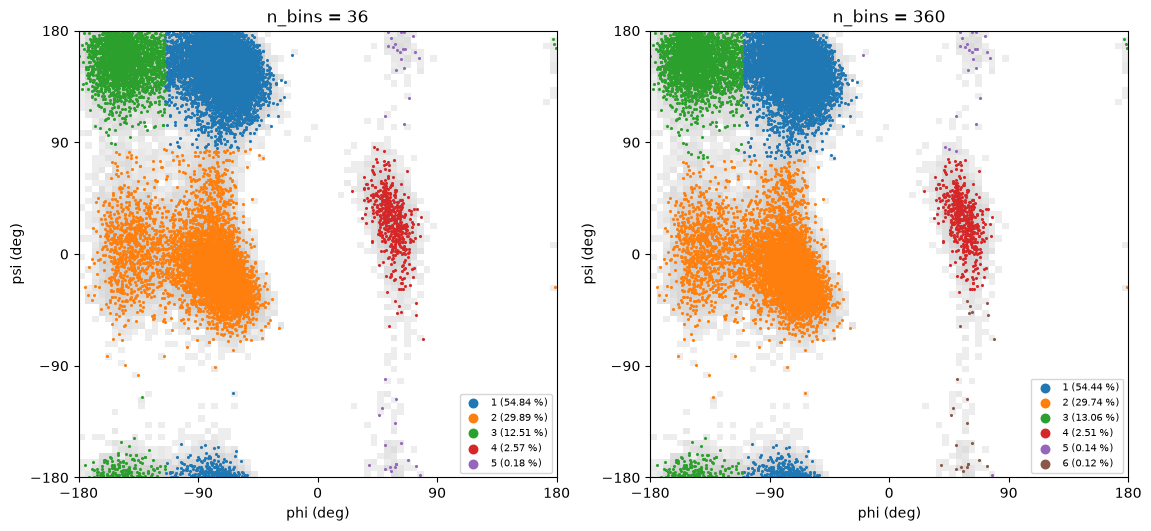

,n_bins,clusters,masses (%),cuts
0,36,5,"[54.84, 29.89, 12.51, 2.57, 0.18]",4
1,72,5,"[54.6, 29.83, 12.81, 2.57, 0.18]",4
2,144,5,"[54.46, 29.82, 12.96, 2.57, 0.19]",4
3,360,6,"[54.44, 29.74, 13.06, 2.51, 0.14, 0.12]",5


In [10]:
by_bins = sweep("n_bins", (36, 72, 144, 360), show=(36, 360))

36 to 144 bins give the same five clusters, with the cuts moved by up to a bin. At 360 bins (1 degree) the
0.18 % strip has empty one-degree bins inside it and is cut in two: a cut through an empty bin needs no
barrier, so the finer the grid the more an empty run is a property of the sample size rather than of the
surface. Keep the bins wide enough that a bin in a basin is never empty.

## 8. `z_min`, `gauge` and `reference`

`z_min` applies only to symmetry-invariant coordinates, and ALA has none. Where a coordinate is an
average over a symmetry group's operations, its modulus |z| says how well the average is defined: where
the images cancel (|z| below `z_min`) the frame is left out of that coordinate's profile, and still
assigned by its value if the coordinate is cut. See
[Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#6-symmetry-invariant-coordinates-used-by-torsion-partitioning).

`gauge` and `reference` set only how `result["aligned_angles"]` is written, which is what `plot_hist` draws:
every frame in the labelling nearest frame `reference`, with `gauge` as in
[Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#7-one-labelling-for-drawing). They never change a cell.

## The clusters, per torsion

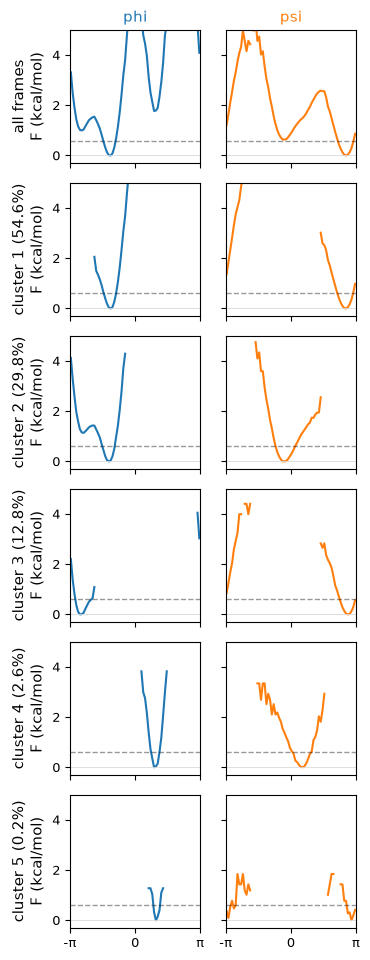

In [11]:
plot_hist(result, n_cluster=5, show_molecule=False, kind="free_energy");

## What this does and does not establish

* **A cluster is a region bounded by barriers in one-dimensional projections.** Two basins that overlap in
  every projection are not separated. A barrier visible only in 2D is invisible to this.
* **A barrier is read from the sampled frames.** Near the floor, with a few hundred frames in a cell, it is
  noisy, and an empty bin may be a property of the sample size (section 7).
* **Every frame is labelled.** The torsion partitioning has no noise code, so a frame in a sparsely sampled
  saddle belongs to whichever side of the cut it lies on.
* **Frame weights are refused**; resample the ensemble first.
* **A cluster is not a metastable state.** Nothing here looks at time.
* **Observed, not tested** (no test reruns these): alanine dipeptide, the five clusters above; c(RGDfV)
  state 0, 3 x 100 000 frames, 15 backbone torsions, 9 clusters at the defaults (see the
  [c(RGDfV) tutorial](https://csy0000.github.io/MD-tools/tutorial/rgdfv/analysis/clustering/)); folic acid dianion, REST2 state 0,
  50 000 frames, 14 torsions, 302 clusters at the defaults and 45 at `mass_floor=0.01`.